# 32 — Détection temporelle ReLUT

Applique le modèle ReLUT *ParkingSearchPrediction* aux segments voiture préparés par l'étape 01 (`prepared_relut_points.parquet`), **restreints aux legs du corpus commun** (`legs/corpus_by_leg.parquet`, mêmes legs que la méthode spatiale), puis :

1. histogrammes des durées de recherche prédites — ensemble des segments, participants sans et avec besoin de chercher (questionnaire PL23) ;
2. tableaux n_segments / temps moyen / temps médian (affichés et exportés en CSV) ;
3. courbes de probabilité d'un échantillon générique de segments, partie en cruising surlignée en rouge pastel ;
4. cartes : les N recherches les plus longues, un échantillon « besoin de chercher », un échantillon « pas besoin de chercher », et l'échantillon générique des courbes ;
5. table par leg `legs/relut_by_leg.parquet` (une ligne par leg, clé `leg_id`) pour la collection interopérable.

Logique : `src/parking_search_prediction/relut_detection.py`. Ligne de commande : `python scripts/32_temporal_detection.py --max-legs 300`.

Sélection par motif : `PURPOSES` (prédiction, run partiel dans `legs/_samples/<run_id>/`) et `TABLE_PURPOSES` (tableaux de parts au-delà des seuils).

In [14]:
CONFIG_NAME = "full_waypoints.yaml"
OUTPUT_DIR = "outputs/pl23"          # sorties de l'étape 01 ; "outputs/declic" pour la rétrocompatibilité

MAX_LEGS = None                       # None = toutes les legs ; sinon tirage aléatoire de MAX_LEGS legs
RANDOM_SEED = 42                     # tirage des legs et des échantillons cartographiés

P_SEARCH = "auto"                    # "auto" (seuils ReLUT selon l'échantillonnage) ou une valeur entre 0 et 1
MAX_SEARCH_DURATION_MINUTES = 15     # recherche limitée aux 15 dernières minutes ; None pour ne pas plafonner

# Groupes « besoin de chercher » (pl23) : variable du questionnaire et catégories de chaque groupe
USE_SURVEY = True                    # False pour declic (pas de questionnaire)
PARKING_VARIABLE = "space_home"      # "space_home" (domicile) ou "space_work" (travail / études)
NO_CRUISE_CATEGORIES = ["Pas de place dédiée, pas besoin de cruise","Place dédiée"]   # ajouter "Place dédiée" pour l'inclure
CRUISE_CATEGORIES = ["Pas de place dédiée, besoin de cruise"]
USER_ID_MAP_FILE = "Data/GPS/pl23/20241120_dump_situee/241120_user_statistics.csv"
SURVEY_FILE = "Data/GPS/pl23/EPFL_vague1_v4.csv"

# Sélection par motif (prédiction) : None = tous les motifs ; ex. ["Travail"] ou ["Travail", "Loisirs"].
# Valeurs de purpose_agg : Travail, Formation, Achats et services, Loisirs, Accompagnement, Retour à la maison, Autres.
# Un run limité à certains motifs écrit relut_by_leg dans legs/_samples/<run_id>/ (la table complète n'est pas écrasée).
PURPOSES = "Retour à la maison"  # None = tous les motifs ; ex. ["Travail"] ou ["Travail", "Loisirs"].
PURPOSE_COLUMN = "purpose_agg"       # "purpose_agg" (motifs regroupés) ou "trip_purpose" (motif détaillé)

# Les legs traitées sont celles du corpus commun (legs/corpus_by_leg.parquet, filtres `leg_filters`
# du YAML, construit à l'étape 01) : exactement les mêmes que pour la méthode spatiale (notebook 22).

N_LONGEST_MAP = 20                   # carte des N recherches prédites les plus longues
N_SAMPLE_MAP = 20                    # taille des échantillons « besoin » / « pas besoin »
N_GENERIC_SAMPLE = 12                # courbes de probabilité + carte « generic sample » (segments tirés au hasard)
WRITE_LEG_TABLE = True               # legs/relut_by_leg.parquet ; avec MAX_LEGS : legs/_samples/<run_id>/

In [15]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import HTML, Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from parking_search_prediction.config import load_config
from parking_search_prediction.leg_collection import load_leg_table
from parking_search_prediction.relut_detection import run_temporal_detection

config = load_config(PROJECT_ROOT / "config" / CONFIG_NAME)
config["paths"]["output_dir"] = OUTPUT_DIR
config["model"].update({"p_search": P_SEARCH, "max_search_duration_minutes": MAX_SEARCH_DURATION_MINUTES})
config["temporal_detection"].update(
    {
        "max_legs": MAX_LEGS,
        "random_seed": RANDOM_SEED,
        "use_survey": USE_SURVEY,
        "parking_variable": PARKING_VARIABLE,
        "no_cruise_categories": NO_CRUISE_CATEGORIES,
        "cruise_categories": CRUISE_CATEGORIES,
        "n_longest_map": N_LONGEST_MAP,
        "n_sample_map": N_SAMPLE_MAP,
        "n_generic_sample": N_GENERIC_SAMPLE,
        "write_leg_table": WRITE_LEG_TABLE,
        "purposes": PURPOSES,
        "purpose_column": PURPOSE_COLUMN,
    }
)
config["leg_matching"]["user_id_map"] = (
    {"file": USER_ID_MAP_FILE, "legs_id_col": "user_id_fors", "waypoints_id_col": "user_id_motiontag"} if USE_SURVEY else None
)
config.setdefault("pl23_survey", {})["survey_file"] = SURVEY_FILE

In [16]:
result = run_temporal_detection(config)
display(pd.Series(result["summary"]["loop_filter"], name="corpus commun"))
pd.Series({k: v for k, v in result["summary"].items() if not isinstance(v, dict)}, name="run")

[relut] corpus commun : 55083 legs — 55351 segments sur 73921 préparés
[relut] motifs ['Retour à la maison'] (purpose_agg) : 25760 legs sur 55031 du corpus
[relut] 25'927 segments sur 25'927 (toutes les legs, motifs Retour à la maison (purpose_agg)) — 14'189'414 points


/Users/maximiliantrique/Documents/Projet_python/PARKING_SEARCH_PREDICTION/src/parking_search_prediction/relut_detection.py:96: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


[relut] 2'000/25'927 segments — 30 s


/Users/maximiliantrique/Documents/Projet_python/PARKING_SEARCH_PREDICTION/src/parking_search_prediction/relut_detection.py:96: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


[relut] 4'000/25'927 segments — 32 s


/Users/maximiliantrique/Documents/Projet_python/PARKING_SEARCH_PREDICTION/src/parking_search_prediction/relut_detection.py:96: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


... (19 outputs left out)

/Users/maximiliantrique/Documents/Projet_python/PARKING_SEARCH_PREDICTION/src/parking_search_prediction/relut_detection.py:96: RuntimeWarning: overflow encountered in exp
  x = 1.0 / (1.0 + np.exp(-x))


[relut] 25'927/25'927 segments — 58 s
[relut] table par leg : /Users/maximiliantrique/Documents/Projet_python/PARKING_SEARCH_PREDICTION/outputs/pl23/legs/_samples/20261116T162430_motifs-Retour-à-la-maison/relut_by_leg.parquet — {'not_car_leg': 465516, 'outside_study_area': 116215, 'other_purpose': 29270, 'evaluated': 25756, 'excluded_by_corpus': 21016, 'no_car_waypoints': 1370, 'last_segment_rejected': 57}


note                      filtres de legs appliqués en amont par le corp...
corpus_legs                                                           55083
segments_before_corpus                                                73921
Name: corpus commun, dtype: object

scope                                     toutes les legs, motifs Retour à la maison (pu...
segments_available                                                                    25927
segments_total                                                                        25927
legs_total                                                                            25760
segments_with_search                                                                  24937
points_total                                                                       14189414
searching_points                                                                     818519
mean_search_duration_minutes                                                       1.116217
median_search_duration_minutes                                                     0.516667
mean_search_start_remaining_distance_m                                             97.86818
purposes                                                               [Retour à

## Durées de recherche prédites

Durée = temps entre le premier point prédit « searching » et la fin du segment ; 0 si aucune recherche n'est détectée. Les tableaux sont exportés dans `reports/32_search_duration_stats.csv` et `reports/32_search_duration_by_parking_category.csv`.

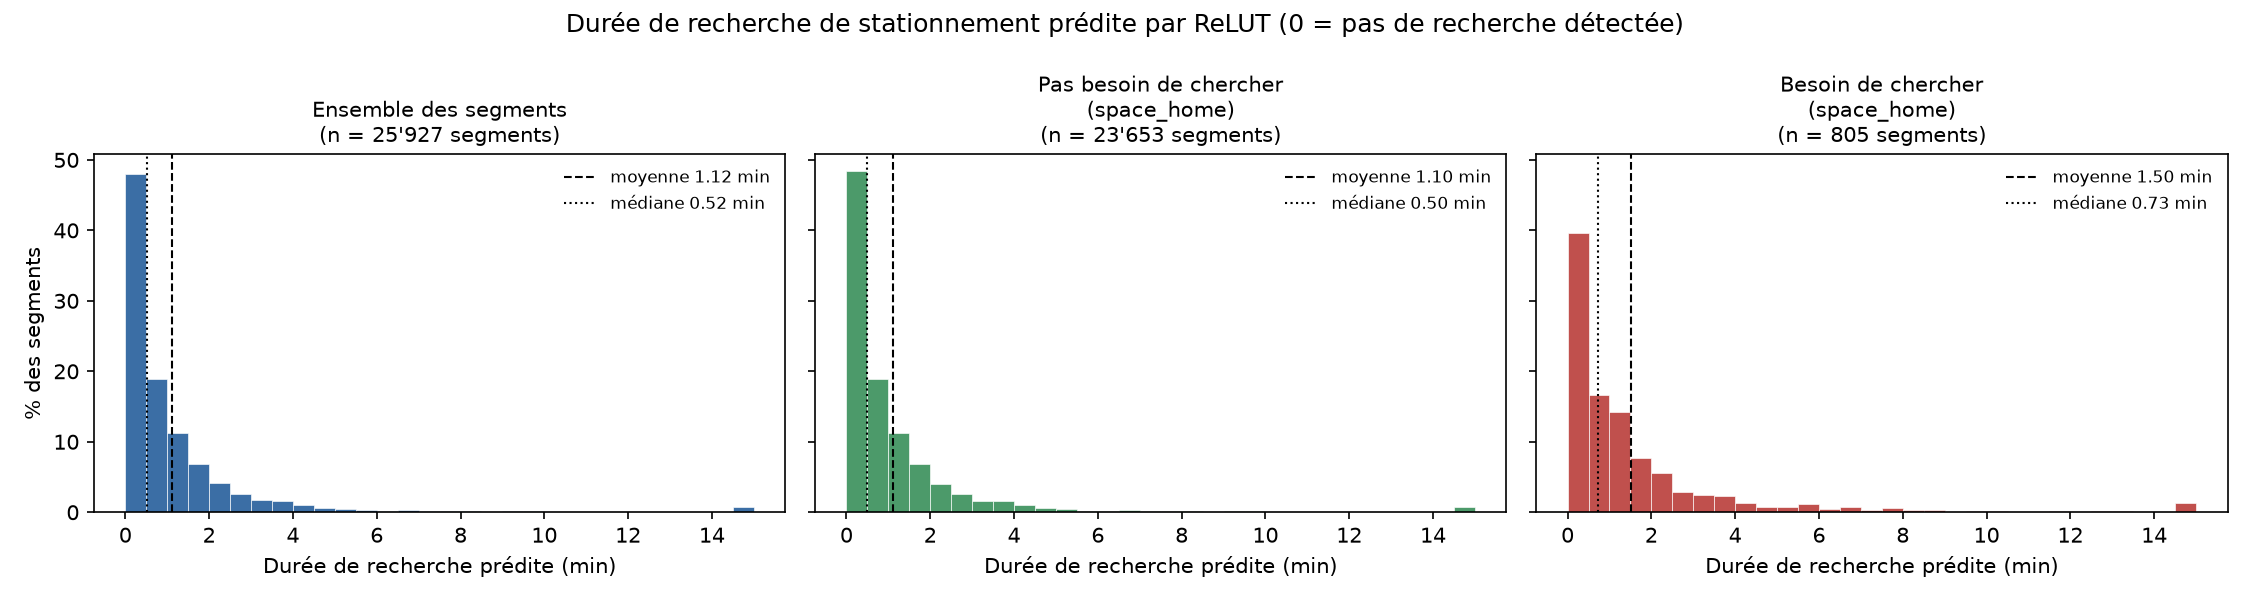

,groupe,n_segments,temps_moyen_min,temps_median_min,n_segments_avec_recherche,part_avec_recherche,temps_moyen_min_si_recherche,temps_median_min_si_recherche
0,Ensemble,25927,1.12,0.52,24937,0.96,1.16,0.57
1,Pas besoin de chercher,23653,1.10,0.50,22752,0.96,1.15,0.57
2,Besoin de chercher,805,1.50,0.73,779,0.97,1.55,0.80


,variable,groupe,n_segments,temps_moyen_min,temps_median_min,n_segments_avec_recherche,part_avec_recherche,temps_moyen_min_si_recherche,temps_median_min_si_recherche
0,space_home,Place dédiée,22274,1.10,0.50,21440,0.96,1.14,0.57
1,space_home,"Pas de place dédiée, pas besoin de cruise",1379,1.14,0.52,1312,0.95,1.19,0.58
2,space_home,Aucun,1444,1.15,0.51,1381,0.96,1.20,0.57
3,space_home,"Pas de place dédiée, besoin de cruise",805,1.50,0.73,779,0.97,1.55,0.80
4,space_home,non renseigné / absent du questionnaire,25,0.61,0.17,25,1.00,0.61,0.17


In [17]:
display(Image(filename=result["summary"]["outputs"]["histograms"]))
display(result["stats"].round(2))
if result["by_category"] is not None:
    display(result["by_category"].round(2))

## Distances de recherche prédites

Distance = somme des distances entre waypoints consécutifs, du point de bascule jusqu'à la fin du segment (mêmes panneaux que les durées : ensemble, puis groupes de stationnement déclaré) ; 0 si aucune recherche n'est détectée. Les distances au-delà du 99ᵉ percentile des segments avec recherche sont regroupées dans la dernière classe. Tableau : `reports/32_search_distance_stats.csv`.

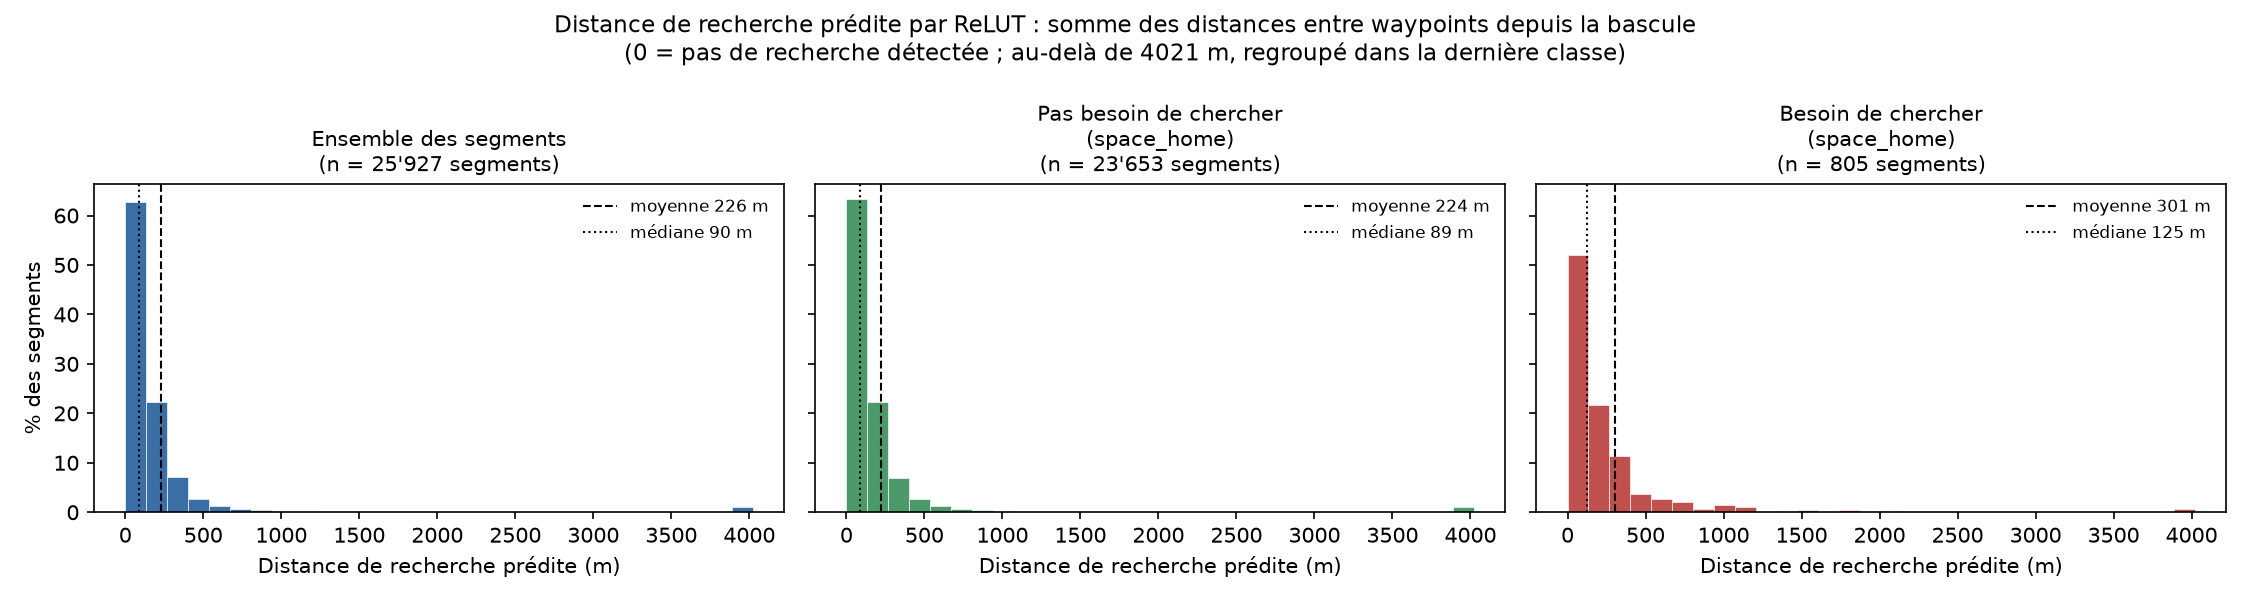

,groupe,n_segments,distance_moyenne_m,distance_mediane_m,n_segments_avec_recherche,distance_moyenne_m_si_recherche,distance_mediane_m_si_recherche,distance_q90_m_si_recherche
0,Ensemble,25927,226.3,90.3,24937,235.3,96.6,352.8
1,Pas besoin de chercher,23653,224.1,88.6,22752,233.0,94.7,343.1
2,Besoin de chercher,805,301.0,125.3,779,311.1,131.9,623.8


In [18]:
display(Image(filename=result["summary"]["outputs"]["distance_histograms"]))
result["distance_stats"].round(1)

## Part des legs au-delà de seuils, par stationnement déclaré

Pour chaque catégorie de `space_home` et de `space_work` (plus « Ensemble »), part des legs évaluées dont la durée (resp. la distance) de recherche prédite **dépasse strictement** chaque seuil ; une leg sans recherche compte pour 0 (le seuil 0 donne donc la part de legs avec recherche). Une colonne par seuil, réglable ci-dessous. `TABLE_PURPOSES` restreint les tables à certains motifs (par défaut les motifs de la prédiction, `PURPOSES`) ; le nom du fichier prend alors le suffixe `_motifs-<motifs>`. Tables enregistrées sous `reports/32_part_au_dela_seuils_<durée|distance>_<variable>.csv`.

In [19]:
from parking_search_prediction.relut_detection import threshold_share_table

DURATION_THRESHOLDS_S = [0, 30, 60, 120, 300, 600]
DISTANCE_THRESHOLDS_M = [0, 100, 200, 500, 1000, 2000]
TABLE_PURPOSES = PURPOSES            # None = tous les motifs ; ex. ["Travail"] (indépendant de la prédiction)

sample_id = result["summary"]["relut_by_leg"]["run_id"] if result["summary"]["relut_by_leg"]["sample"] else None

share_tables = {}
for variable in ("space_home", "space_work"):
    for measure, thresholds in (("duration", DURATION_THRESHOLDS_S), ("distance", DISTANCE_THRESHOLDS_M)):
        table = threshold_share_table(config, variable, measure, thresholds, sample_run_id=sample_id,
                                      purposes=TABLE_PURPOSES, purpose_column=PURPOSE_COLUMN)
        share_tables[(variable, measure)] = table
        share_columns = [c for c in table.columns if c.startswith(">")]
        print(f"{variable} — {'durée' if measure == 'duration' else 'distance'} de recherche"
              + (f" — motifs : {', '.join(TABLE_PURPOSES)}" if TABLE_PURPOSES else ""))
        display(table.style.format({c: "{:.1%}" for c in share_columns}).hide(axis="index"))

space_home — durée de recherche — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_home,n_legs,> 0 s,> 30 s,> 60 s,> 120 s,> 300 s,> 600 s
Ensemble,25756,85.5%,50.2%,32.1%,14.4%,3.0%,1.2%
Place dédiée,22134,85.3%,49.9%,31.6%,14.0%,2.9%,1.2%
Aucun,1431,87.1%,50.2%,32.4%,15.8%,3.6%,1.0%
"Pas de place dédiée, pas besoin de cruise",1371,83.5%,50.6%,32.7%,15.8%,2.8%,1.3%
"Pas de place dédiée, besoin de cruise",795,90.1%,58.5%,42.1%,21.0%,5.8%,1.8%
non renseigné,25,80.0%,24.0%,16.0%,12.0%,0.0%,0.0%


space_home — distance de recherche — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_home,n_legs,> 0 m,> 100 m,> 200 m,> 500 m,> 1000 m,> 2000 m
Ensemble,25756,85.5%,47.0%,23.4%,5.5%,2.5%,1.6%
Place dédiée,22134,85.4%,46.4%,22.7%,5.1%,2.3%,1.6%
Aucun,1431,87.1%,52.2%,27.5%,7.0%,3.0%,1.5%
"Pas de place dédiée, pas besoin de cruise",1371,83.4%,46.4%,23.8%,6.2%,3.2%,1.8%
"Pas de place dédiée, besoin de cruise",795,90.1%,56.5%,36.0%,12.3%,5.2%,2.0%
non renseigné,25,80.0%,28.0%,12.0%,4.0%,0.0%,0.0%


space_work — durée de recherche — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_work,n_legs,> 0 s,> 30 s,> 60 s,> 120 s,> 300 s,> 600 s
Ensemble,25756,85.5%,50.2%,32.1%,14.4%,3.0%,1.2%
non renseigné,16805,85.5%,50.0%,31.7%,14.1%,3.0%,1.2%
"Pas de place dédiée, pas besoin de cruise",5911,84.2%,50.6%,32.8%,15.1%,3.2%,1.3%
"Pas de place dédiée, besoin de cruise",1954,87.6%,49.5%,32.9%,15.6%,2.7%,0.9%
Place dédiée,1086,87.8%,50.8%,31.9%,13.6%,3.0%,1.3%


space_work — distance de recherche — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_work,n_legs,> 0 m,> 100 m,> 200 m,> 500 m,> 1000 m,> 2000 m
Ensemble,25756,85.5%,47.0%,23.4%,5.5%,2.5%,1.6%
non renseigné,16805,85.5%,46.7%,23.5%,5.4%,2.4%,1.6%
"Pas de place dédiée, pas besoin de cruise",5911,84.4%,45.7%,23.0%,5.9%,2.8%,1.8%
"Pas de place dédiée, besoin de cruise",1954,87.8%,52.1%,24.0%,5.9%,2.6%,1.4%
Place dédiée,1086,87.8%,48.3%,23.3%,5.2%,2.3%,1.6%


## Part des legs au-delà d'un seuil, par stationnement déclaré

Pour chaque catégorie de `space_home` et de `space_work` : part des legs évaluées dont la **durée** (minutes) ou la **distance** (mètres) de recherche prédite atteint chaque seuil. Une colonne par seuil ; les legs sans recherche comptent pour 0. Comptage par leg, non pondéré. Même sélection par motif que la cellule précédente (`TABLE_PURPOSES`). Tables enregistrées sous `reports/32_part_legs_<durée|distance>_par_<variable>.csv`.

In [20]:
from parking_search_prediction.relut_detection import share_above_thresholds

DURATION_THRESHOLDS_MIN = [0.5, 1, 2, 3, 5, 10]
DISTANCE_THRESHOLDS_M = [100, 200, 500, 1000, 2000]
THRESHOLD_VARIABLES = ["space_home", "space_work"]
# TABLE_PURPOSES : défini dans la cellule précédente (None = tous les motifs)

sample_id = result["summary"]["relut_by_leg"]["run_id"] if result["summary"]["relut_by_leg"]["sample"] else None
for variable in THRESHOLD_VARIABLES:
    for quantity, thresholds in (("duration", DURATION_THRESHOLDS_MIN), ("distance", DISTANCE_THRESHOLDS_M)):
        table = share_above_thresholds(config, variable, quantity, thresholds, sample_run_id=sample_id,
                                       purposes=TABLE_PURPOSES, purpose_column=PURPOSE_COLUMN)
        share_columns = [c for c in table.columns if c.startswith("≥")]
        print(f"{variable} — {'durée' if quantity == 'duration' else 'distance'} de recherche prédite"
              + (f" — motifs : {', '.join(TABLE_PURPOSES)}" if TABLE_PURPOSES else ""))
        display(table.style.format({c: "{:.1%}" for c in share_columns}).hide(axis="index"))

space_home — durée de recherche prédite — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_home,n_legs,≥ 0.5 min,≥ 1 min,≥ 2 min,≥ 3 min,≥ 5 min,≥ 10 min
toutes les legs,25756,51.9%,32.9%,14.7%,7.9%,3.1%,1.2%
Aucun,1431,52.9%,32.8%,15.8%,8.9%,3.6%,1.0%
"Pas de place dédiée, besoin de cruise",795,60.1%,43.3%,21.1%,12.7%,5.8%,1.8%
"Pas de place dédiée, pas besoin de cruise",1371,51.9%,33.8%,16.0%,9.0%,2.9%,1.3%
Place dédiée,22134,51.6%,32.5%,14.3%,7.6%,2.9%,1.2%
non renseigné,25,24.0%,16.0%,12.0%,8.0%,0.0%,0.0%


space_home — distance de recherche prédite — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_home,n_legs,≥ 100 m,≥ 200 m,≥ 500 m,≥ 1000 m,≥ 2000 m
toutes les legs,25756,47.0%,23.4%,5.5%,2.5%,1.6%
Aucun,1431,52.2%,27.5%,7.0%,3.0%,1.5%
"Pas de place dédiée, besoin de cruise",795,56.5%,36.0%,12.3%,5.2%,2.0%
"Pas de place dédiée, pas besoin de cruise",1371,46.4%,23.8%,6.2%,3.2%,1.8%
Place dédiée,22134,46.4%,22.7%,5.1%,2.3%,1.6%
non renseigné,25,28.0%,12.0%,4.0%,0.0%,0.0%


space_work — durée de recherche prédite — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_work,n_legs,≥ 0.5 min,≥ 1 min,≥ 2 min,≥ 3 min,≥ 5 min,≥ 10 min
toutes les legs,25756,51.9%,32.9%,14.7%,7.9%,3.1%,1.2%
"Pas de place dédiée, besoin de cruise",1954,52.1%,33.5%,16.1%,8.3%,2.7%,0.9%
"Pas de place dédiée, pas besoin de cruise",5911,52.1%,33.7%,15.3%,8.6%,3.2%,1.3%
Place dédiée,1086,52.3%,33.1%,14.0%,7.6%,3.2%,1.3%
non renseigné,16805,51.8%,32.5%,14.3%,7.7%,3.0%,1.2%


space_work — distance de recherche prédite — motifs : R, e, t, o, u, r,  , à,  , l, a,  , m, a, i, s, o, n


space_work,n_legs,≥ 100 m,≥ 200 m,≥ 500 m,≥ 1000 m,≥ 2000 m
toutes les legs,25756,47.0%,23.4%,5.5%,2.5%,1.6%
"Pas de place dédiée, besoin de cruise",1954,52.1%,24.0%,5.9%,2.6%,1.4%
"Pas de place dédiée, pas besoin de cruise",5911,45.7%,23.0%,5.9%,2.8%,1.8%
Place dédiée,1086,48.3%,23.3%,5.2%,2.3%,1.6%
non renseigné,16805,46.7%,23.5%,5.4%,2.4%,1.6%


## Courbes de probabilité — échantillon générique

`N_GENERIC_SAMPLE` segments tirés au hasard (graine `RANDOM_SEED`). Rouge pastel : partie prédite en cruising, à partir du point de bascule (trait pointillé vertical). Ligne pointillée horizontale : seuil de probabilité utilisé, indiqué en légende (avec `P_SEARCH = "auto"`, il dépend de l'échantillonnage médian du segment). La bascule peut être plus tardive que le premier dépassement du seuil si la recherche est plafonnée à `MAX_SEARCH_DURATION_MINUTES`. Liste des segments : `reports/32_generic_sample_segments.csv` ; mêmes segments sur la carte `32_generic_sample.html`.

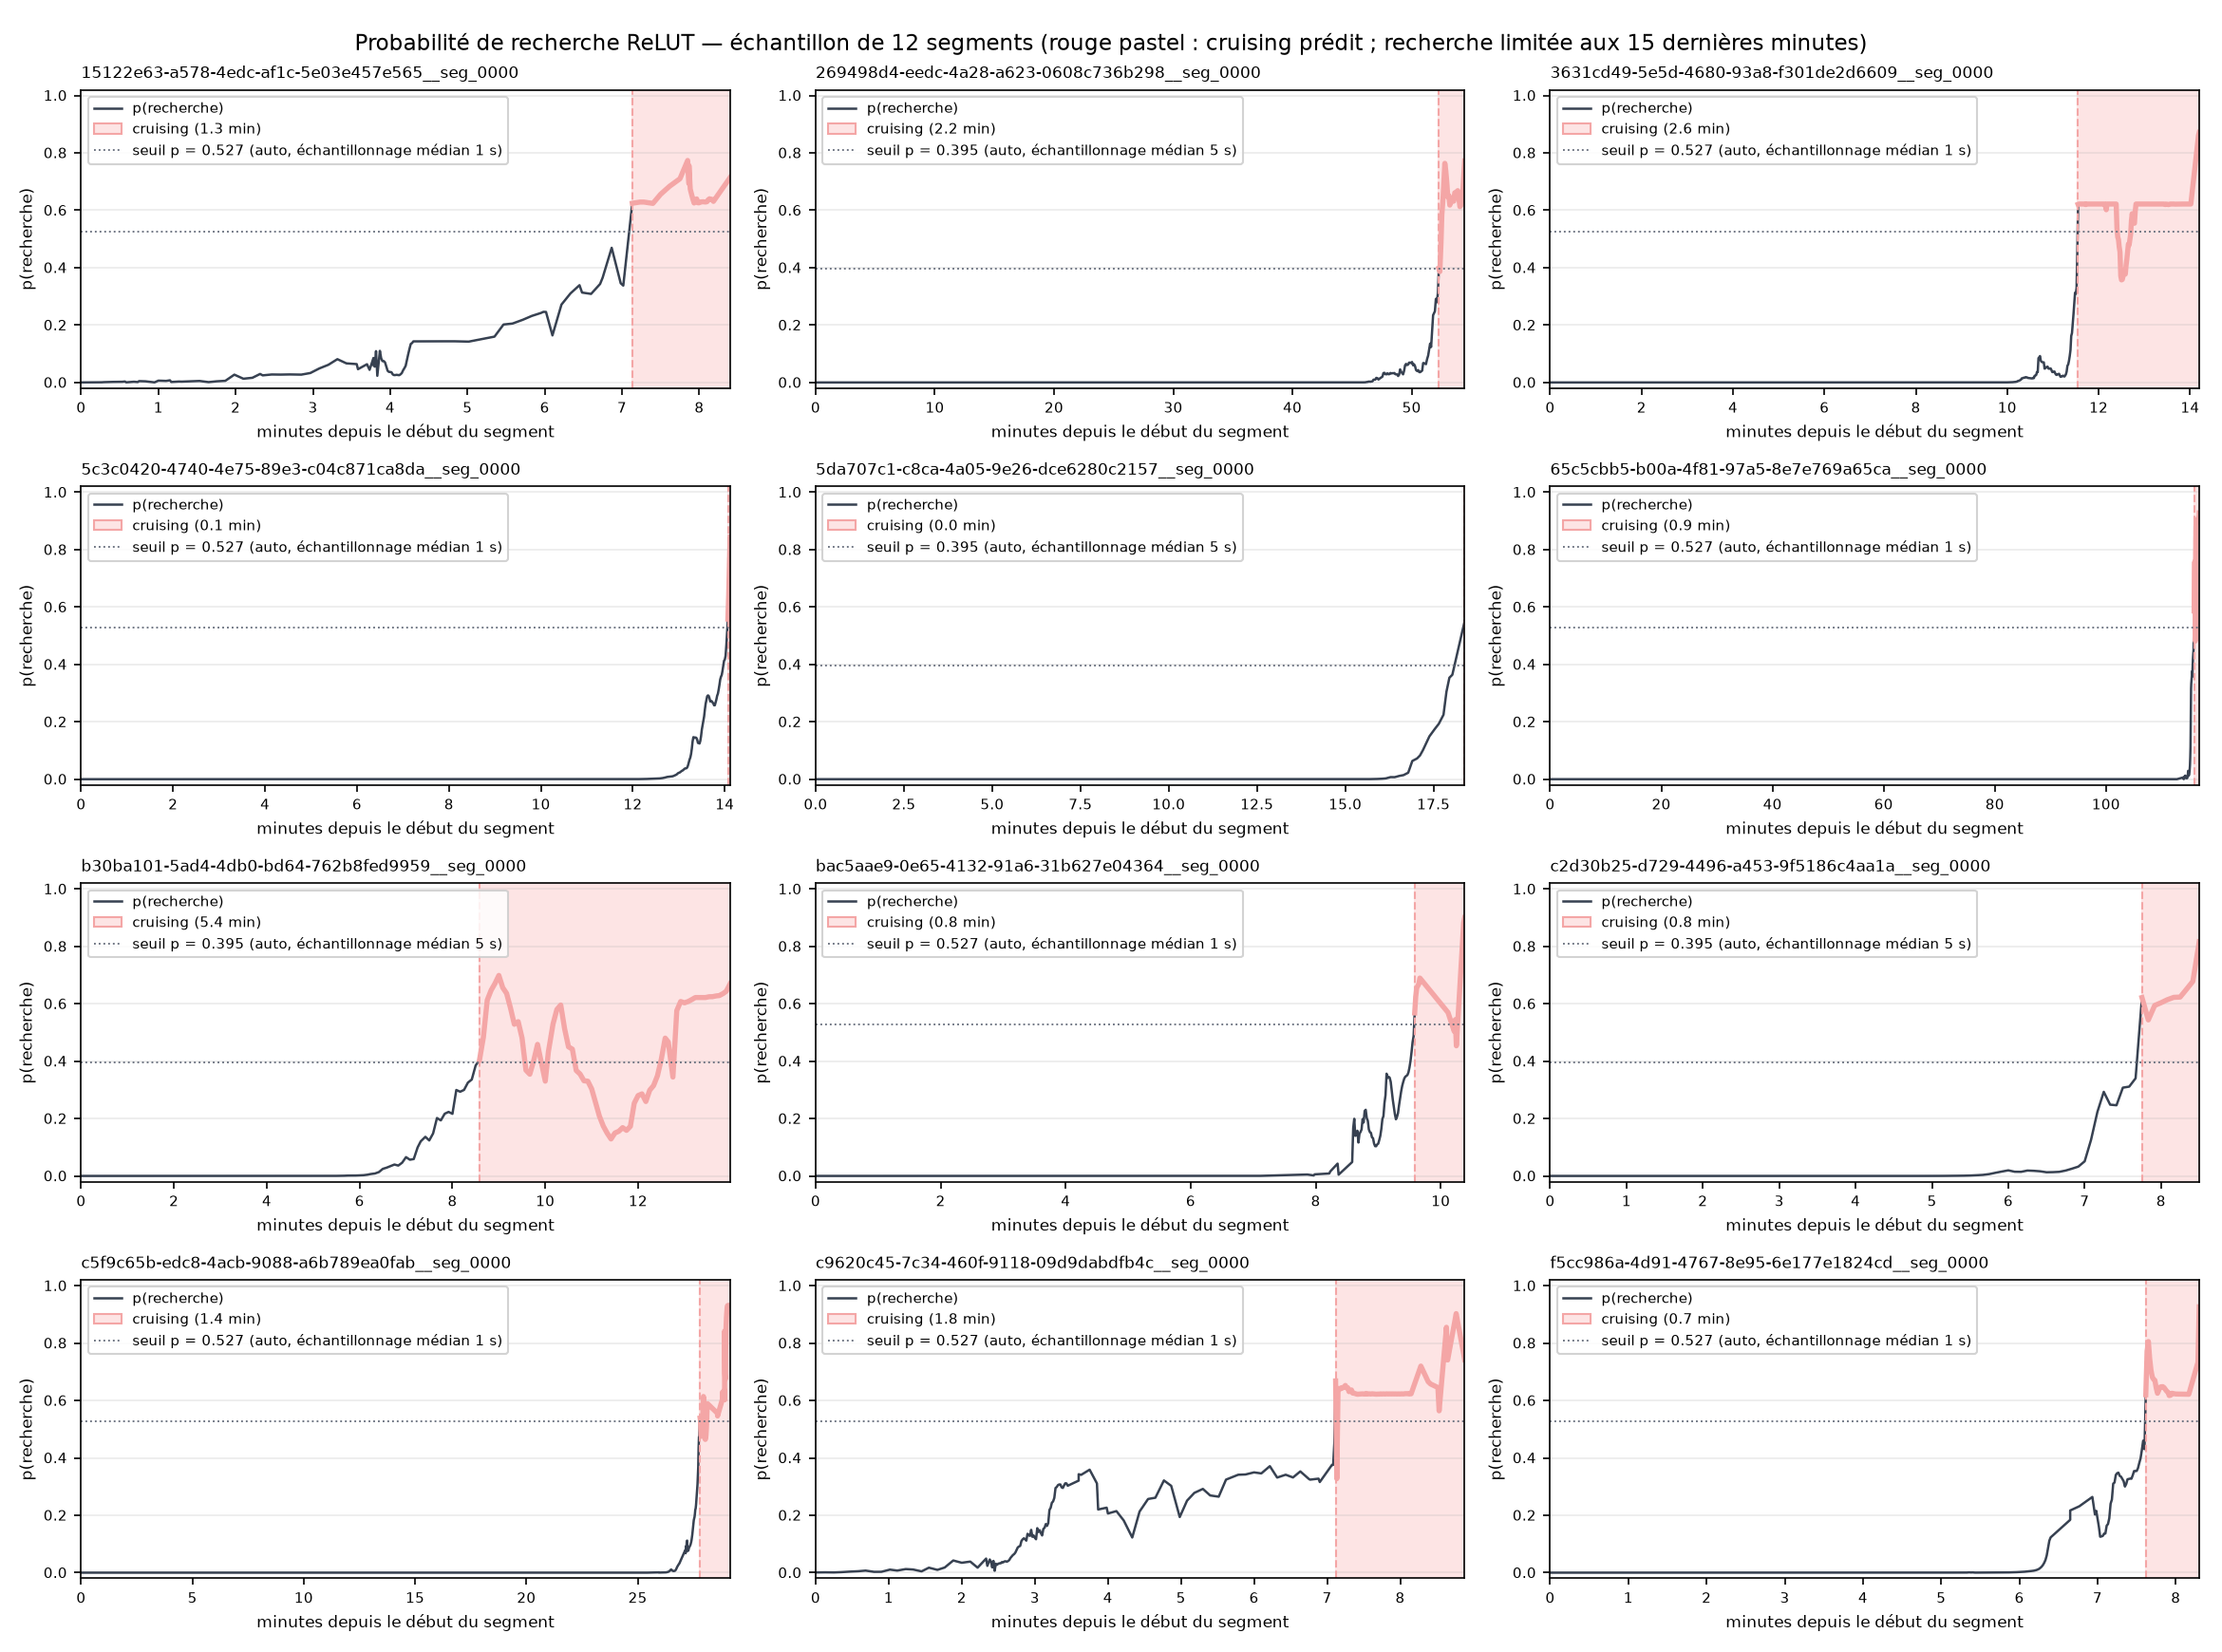

In [21]:
if result["summary"]["outputs"]["probability_curves"]:
    display(Image(filename=result["summary"]["outputs"]["probability_curves"]))

## Cartes

Traces en bleu (conduite) et rouge (recherche prédite), drapeau au début de la recherche. Les cartes s'ouvrent dans le navigateur.

In [22]:
for name, path in result["summary"]["outputs"]["maps"].items():
    if path:
        display(HTML(f'<p><a href="{Path(path).as_uri()}" target="_blank">{Path(path).name}</a></p>'))

## Table par leg et vue d'assemblage

`relut_by_leg` contient **toutes les legs** (clé `leg_id`). Pour chaque leg voiture, le **dernier segment** est retenu, sans repli sur un segment antérieur. `relut_status` dit s'il a été prédit (`evaluated`) ou pourquoi il ne l'a pas été (`not_car_leg`, `no_car_waypoints`, `outside_study_area`, `no_segment`, `last_segment_rejected`, `last_segment_loop`, `not_sampled`, `other_purpose` si `PURPOSES` est renseigné). Règle de la collection : **0 = évalué sans recherche, NaN = non évalué**. Distances : `relut_search_distance_m` le long de la trace depuis la bascule, `relut_straight_line_distance_m` à vol d'oiseau entre la bascule et le stationnement.

`load_leg_table` assemble `legs_enriched` (trip, motif, moment, questionnaire, marche après la voiture) et les tables demandées par jointure sur `leg_id`. Dictionnaire généré : `legs/_dictionary.csv` ; provenance : `legs/_manifest.json`.

In [23]:
info = result["summary"]["relut_by_leg"]
if info:
    display(pd.Series(info["status_counts"], name="relut_status"))
    legs = load_leg_table(config, ["relut_by_leg"], sample_run_id=info["run_id"] if info["sample"] else None)
    car = legs[legs["relut_status"].ne("not_car_leg")]
    display(car.groupby("relut_status", dropna=False)[["relut_search_duration_s", "relut_search_distance_m"]].agg(["count", "mean", "median"]).round(1))
    shown = [c for c in ["leg_id", "purpose_agg", "space_home", "relut_search_duration_s", "relut_search_distance_m",
                         "relut_straight_line_distance_m"] if c in legs.columns]
    display(legs.loc[legs["relut_status"].eq("evaluated"), shown].head())

not_car_leg              465516
outside_study_area       116215
other_purpose             29270
evaluated                 25756
excluded_by_corpus        21016
no_car_waypoints           1370
last_segment_rejected        57
Name: relut_status, dtype: int64

[legs] relut_by_leg : 659200 lignes — run 20261116T162430_motifs-Retour-à-la-maison — 2026-11-16T15:24:33+00:00


relut_search_duration_s               \
                                        count  mean median   
relut_status                                                 
evaluated                               25756  66.1   31.0   
excluded_by_corpus                          0   NaN    NaN   
last_segment_rejected                       0   NaN    NaN   
no_car_waypoints                            0   NaN    NaN   
other_purpose                               0   NaN    NaN   
outside_study_area                          0   NaN    NaN   

                      relut_search_distance_m                
                                        count   mean median  
relut_status                                                 
evaluated                               25756  226.5   90.2  
excluded_by_corpus                          0    NaN    NaN  
last_segment_rejected                       0    NaN    NaN  
no_car_waypoints                            0    NaN    NaN  
other_purpose                               0    NaN    NaN  
outside_study_area                          0    NaN    NaN

,leg_id,purpose_agg,space_home,relut_search_duration_s,relut_search_distance_m,relut_straight_line_distance_m
921,edc1f69d-3b52-4f6a-9d79-7de97a852bb3,Retour à la maison,Place dédiée,299.0,277.557267,51.099419
935,77ea7532-cfc5-4a17-8335-91efea4a3f84,Retour à la maison,Place dédiée,9.0,34.381665,25.624864
938,4d744bd2-d0c1-4164-9ecd-31b9db34540c,Retour à la maison,Place dédiée,32.0,81.405152,34.528438
940,2495d1aa-712e-4885-bff1-6e60bc832e9f,Retour à la maison,Place dédiée,28.0,160.189350,117.800275
952,e12c6c8f-2a8a-479d-873c-b1b4a8c0a397,Retour à la maison,Place dédiée,4.0,27.190203,24.247802
